UTS Graf Sains Data

Nama: Kezia Joice Cicilia Sibarani | NIM: 23031554191

Tugas: memasukkan data belanja online (RetailRocket) ke Neo4j, mengubahnya jadi matriks, menghitung kemiripan, lalu membuat rekomendasi KNN dan mengukur kualitasnya.
- **P1 (data latih):** 26/05/2015 – 14/08/2015
- **P2 (data uji):** 15/08/2015 – 04/09/2015

In [6]:
from neo4j import GraphDatabase
from getpass import getpass

URI = "bolt://localhost:7687"
AUTH = ("neo4j", getpass("Password Neo4j: "))

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Terhubung!")

Terhubung!


In [4]:
import pandas as pd

df = pd.read_csv("events.csv")
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

print(df.shape)
print(df["datetime"].min(), "sampai", df["datetime"].max())
print(df["event"].value_counts())
df.head()

(2756101, 6)
2015-05-03 03:00:04.384000 sampai 2015-09-18 02:59:47.788000
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


In [ ]:
# 2) Definisi periode (akhir inklusif -> batas atas = tanggal akhir + 1 hari)
P1_START, P1_END = "2015-05-26", "2015-08-15"   # training: 26/05 s.d. 14/08
P2_START, P2_END = "2015-08-15", "2015-09-05"   # testing : 15/08 s.d. 04/09

# 3) Filter berdasarkan timestamp
p1 = df[(df["datetime"] >= P1_START) & (df["datetime"] < P1_END)].copy()
p2 = df[(df["datetime"] >= P2_START) & (df["datetime"] < P2_END)].copy()

# 4) Validasi: rentang aktual dan tidak ada tumpang tindih
for nama, d in [("P1", p1), ("P2", p2)]:
    print(f"{nama}: {d.shape[0]:,} baris | "
          f"{d['visitorid'].nunique():,} visitor | "
          f"{d['itemid'].nunique():,} item")
    print(f"   rentang: {d['datetime'].min()} s.d. {d['datetime'].max()}")
    print(d["event"].value_counts().to_string(), "\n")

assert p1["datetime"].max() < p2["datetime"].min(), "P1 dan P2 tumpang tindih!"

# 5) Rapikan transactionid agar tidak tersimpan sebagai 123.0
for d in (p1, p2):
    d["transactionid"] = d["transactionid"].astype("Int64")

# 6) Simpan ke CSV (kolom bantu datetime tidak ikut, timestamp asli tetap ada)
p1.drop(columns="datetime").to_csv("events_p1.csv", index=False)
p2.drop(columns="datetime").to_csv("events_p2.csv", index=False)
print("Tersimpan: events_p1.csv dan events_p2.csv")

# 7) Irisan visitor (penting untuk soal 2.2: pemilihan user acak)
irisan = set(p1["visitorid"]) & set(p2["visitorid"])
print("Visitor di P1 dan juga di P2:", len(irisan))

P1: 1,678,419 baris | 868,935 visitor | 190,110 item
   rentang: 2015-05-26 00:00:05.046000 s.d. 2015-08-14 23:59:56.673000
event
view           1622506
addtocart        42101
transaction      13812 

P2: 372,767 baris | 210,955 visitor | 92,457 item
   rentang: 2015-08-15 00:00:07.484000 s.d. 2015-09-04 23:59:59.493000
event
view           359652
addtocart        9892
transaction      3223 

Tersimpan: events_p1.csv dan events_p2.csv
Visitor di P1 dan juga di P2: 16766


2.1 Wrangling dan EDA

Soal 1 dan 2 : Menentukan periode dan menyimpan data

Jawaban: data dibagi dua periode berdasarkan timestamp.

| | Periode | Baris | Visitor | Item |
|---|---|---|---|---|
| P1 (latih) | 26/05 – 14/08/2015 | 1.678.419 | 868.935 | 190.110 |
| P2 (uji) | 15/08 – 04/09/2015 | 372.767 | 210.955 | 92.457 |

- Timestamp aslinya dalam milidetik, jadi diubah ke tanggal dengan `pd.to_datetime(..., unit="ms")`.
- P2 sengaja setelah P1, supaya data masa depan tidak bocor ke data latih.
- Hasil disimpan ke `events_p1.csv` dan `events_p2.csv`.
- Ada **16.766 visitor** yang muncul di P1 dan P2, dipakai untuk memilih user di bagian Analytics.

In [ ]:
HAPUS_DB = False

if HAPUS_DB:
    total = 0
    while True:
        rec, _, _ = driver.execute_query(
            "MATCH ()-[r]->() WITH r LIMIT 20000 DELETE r RETURN count(*) AS c", database_="neo4j")
        if rec[0]["c"] == 0: break
        total += rec[0]["c"]
    while True:
        rec, _, _ = driver.execute_query(
            "MATCH (n) WITH n LIMIT 20000 DELETE n RETURN count(*) AS c", database_="neo4j")
        if rec[0]["c"] == 0: break
        total += rec[0]["c"]
    print("Database dikosongkan. Total terhapus:", total)
else:
    print("Dilewati (HAPUS_DB = False)")

Dilewati (HAPUS_DB = False)


In [6]:
with driver.session(database="neo4j") as session:
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS "
                "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS "
                "FOR (i:Item) REQUIRE i.itemId IS UNIQUE")
print("Constraint siap")

Constraint siap


In [8]:
def import_batch(tx, batch):
    # 1) Node Visitor dan Item
    tx.run("""
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    """, batch=batch)

    # 2) Relasi VIEWED
    tx.run("""
    UNWIND $batch AS row
    WITH row WHERE row.event = 'view'
    MATCH (v:Visitor {visitorId: row.visitorid})
    MATCH (i:Item {itemId: row.itemid})
    CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    """, batch=batch)

    # 3) Relasi ADDED_TO_CART
    tx.run("""
    UNWIND $batch AS row
    WITH row WHERE row.event = 'addtocart'
    MATCH (v:Visitor {visitorId: row.visitorid})
    MATCH (i:Item {itemId: row.itemid})
    CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    """, batch=batch)

    # 4) Relasi BOUGHT
    tx.run("""
    UNWIND $batch AS row
    WITH row WHERE row.event = 'transaction'
    MATCH (v:Visitor {visitorId: row.visitorid})
    MATCH (i:Item {itemId: row.itemid})
    CREATE (v)-[:BOUGHT {timestamp: row.timestamp,
                         transactionId: row.transactionid}]->(i)
    """, batch=batch)

print("import_batch siap:", callable(import_batch))

import_batch siap: True


In [ ]:
import pandas as pd
from tqdm import tqdm

batch_size = 10000
total_rows = sum(1 for _ in open("events_p1.csv")) - 1
total_chunks = total_rows // batch_size + 1
print(f"Total baris: {total_rows:,}")

chunks = pd.read_csv("events_p1.csv", chunksize=batch_size)

with driver.session(database="neo4j") as session:
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor P1"):
        chunk["transactionid"] = chunk["transactionid"].fillna(-1).astype(int)
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Impor selesai")

Total baris: 1,678,419


Mengimpor P1: 100%|██████████| 168/168 [08:08<00:00,  2.91s/it]

Impor selesai


Memasukkan data P1 ke Neo4j
Data P1 dimasukkan per 10.000 baris (*batch*) supaya tidak kehabisan memori. Sebelumnya dibuat *constraint* agar `MERGE` cepat. Tiap baris menjadi relasi `VIEWED`, `ADDED_TO_CART`, atau `BOUGHT`. Sel hapus dan impor diberi saklar `False` supaya tidak sengaja terjalankan ulang (relasi bisa ganda).

In [10]:
rec, _, _ = driver.execute_query(
    "MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah", database_="neo4j")
for r in rec: print(r["jenis_simpul"], r["jumlah"])

print("---")
rec, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah", database_="neo4j")
for r in rec: print(r["jenis_relasi"], r["jumlah"])

Visitor 868935
Item 190110
---
VIEWED 1622506
ADDED_TO_CART 42101
BOUGHT 13812


Soal 3 Komposisi subgraph

Cypher yang dipakai:
- `MATCH (n) RETURN labels(n)[0], count(n)` → hitung simpul per jenis (`labels` = jenis simpul).
- `MATCH ()-[r]->() RETURN type(r), count(r)` → hitung relasi per jenis (`type` = nama relasi).

Jawaban:
| Jenis | Jumlah |
|---|---|
| Simpul Visitor | 868.935 |
| Simpul Item | 190.110 |
| Relasi VIEWED | 1.622.506 |
| Relasi ADDED_TO_CART | 42.101 |
| Relasi BOUGHT | 13.812 |

Total relasi 1.678.419 sama dengan jumlah baris P1, jadi tidak ada data hilang atau ganda. Grafnya (Visitor → Item), dan hampir 97% interaksinya hanya *view*.

In [3]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

p1 = pd.read_csv("events_p1.csv")

bobot = {"view": 1, "addtocart": 3, "transaction": 5}
p1["w"] = p1["event"].map(bobot)

user_ids = p1["visitorid"].astype("category")
item_ids = p1["itemid"].astype("category")

X = csr_matrix(
    (p1["w"].values, (user_ids.cat.codes, item_ids.cat.codes)),
    shape=(user_ids.cat.categories.size, item_ids.cat.categories.size),
)

n_user, n_item = X.shape
nnz = X.nnz
print(f"Dimensi        : {n_user:,} user x {n_item:,} item")
print(f"Sel terisi     : {nnz:,}")
print(f"Sparsity       : {(1 - nnz/(n_user*n_item))*100:.4f}%")
print(f"Memori sparse  : {(X.data.nbytes + X.indices.nbytes + X.indptr.nbytes)/1e6:.1f} MB")
print(f"Memori dense   : {n_user*n_item*8/1e9:,.0f} GB")
print(f"Rata-rata item per user : {nnz/n_user:.2f}")
print(f"Rata-rata user per item : {nnz/n_item:.2f}")

Dimensi        : 868,935 user x 190,110 item
Sel terisi     : 1,308,426
Sparsity       : 99.9992%
Memori sparse  : 19.2 MB
Memori dense   : 1,322 GB
Rata-rata item per user : 1.51
Rata-rata user per item : 6.88


### Kenapa memakai matriks *sparse*, bukan vektor biasa?

Matriks User × Item ini hampir seluruhnya kosong (sparsity 99,9992%). Sel kosong artinya user tidak punya aktivitas pada item itu, dan nilainya 0.

| Cara simpan | Yang disimpan | Memori |
|---|---|---|
| **Dense** (vektor/tabel biasa) | **Semua** sel, ± 165 miliar angka (termasuk yang 0) | ± 1.322 GB |
| **Sparse** (`csr_matrix`) | **Hanya sel yang terisi** (1.308.426 sel) beserta posisinya | **19,2 MB** |

- Sparse **menghemat memori** sekitar 69 ribu kali, karena tidak menyimpan angka nol.
- Perhitungan seperti normalisasi dan cosine juga **lebih cepat**, karena hanya memproses sel yang terisi.
- **Tidak ada informasi yang hilang**: sel yang tidak disimpan memang bernilai 0.

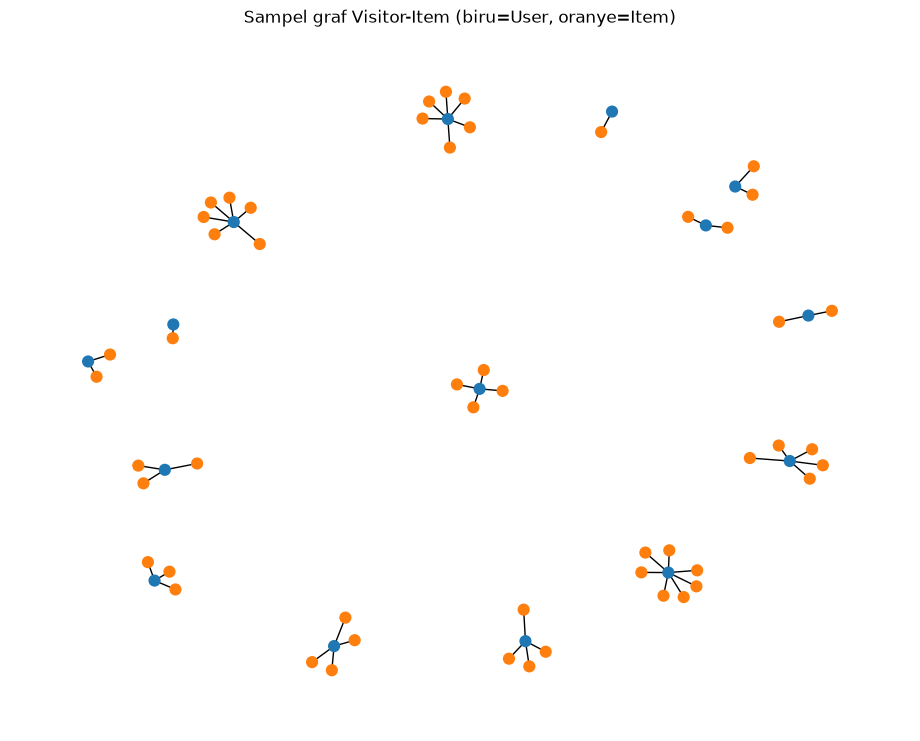

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

# Plot soal 4: sampel user aktif
cnt = p1.groupby("visitorid").size()
aktif = cnt[cnt >= 5].sample(15, random_state=42).index
sub = p1[p1["visitorid"].isin(aktif)].drop_duplicates(["visitorid", "itemid"])

G = nx.Graph()
for _, r in sub.iterrows():
    G.add_edge(f"U{r.visitorid}", f"I{r.itemid}")
warna = ["tab:blue" if n.startswith("U") else "tab:orange" for n in G.nodes]
plt.figure(figsize=(9, 7))
nx.draw_spring(G, node_color=warna, node_size=60, with_labels=False)
plt.title("Sampel graf Visitor-Item (biru=User, oranye=Item)")
plt.show()

Soal 4 VSM untuk User (User × Item)

Tiap user dijadikan vektor sebanyak jumlah item. Isinya bobot: view = 1, addtocart = 3, transaction = 5 (makin kuat minatnya, makin besar bobotnya). Disimpan sebagai matriks *sparse*.

Jawaban:
- Shape: 868.935 × 190.110
- Sel terisi: 1.308.426 → sparsity 99,9992% (hampir semua kosong)
- Memori: sparse 19,2 MB vs dense 1.322 GB → sparse wajib dipakai
- Rata-rata 1,51 item per user

Sebagian besar user hanya punya 1 item, jadi vektornya sangat pendek. Plot di atas hanya sampel 15 user aktif (biru = user, oranye = item), karena seluruh graf terlalu besar.

In [5]:
X_item = X.T.tocsr()

n_item, n_user = X_item.shape
nnz = X_item.nnz
print(f"Dimensi        : {n_item:,} item x {n_user:,} user")
print(f"Sel terisi     : {nnz:,}")
print(f"Sparsity       : {(1 - nnz/(n_item*n_user))*100:.4f}%")
print(f"Memori sparse  : {(X_item.data.nbytes + X_item.indices.nbytes + X_item.indptr.nbytes)/1e6:.1f} MB")

user_deg = np.diff(X.indptr)        # jumlah item per user
item_deg = np.diff(X_item.indptr)   # jumlah user per item

print("\nUser dengan >=2 item :", (user_deg >= 2).sum(), f"({(user_deg>=2).mean()*100:.1f}%)")
print("User dengan >=5 item :", (user_deg >= 5).sum())
print("Item dengan >=2 user :", (item_deg >= 2).sum(), f"({(item_deg>=2).mean()*100:.1f}%)")
print("Item dengan >=5 user :", (item_deg >= 5).sum())

Dimensi        : 190,110 item x 868,935 user
Sel terisi     : 1,308,426
Sparsity       : 99.9992%
Memori sparse  : 16.5 MB

User dengan >=2 item : 170734 (19.6%)
User dengan >=5 item : 23540
Item dengan >=2 user : 116886 (61.5%)
Item dengan >=5 user : 57589


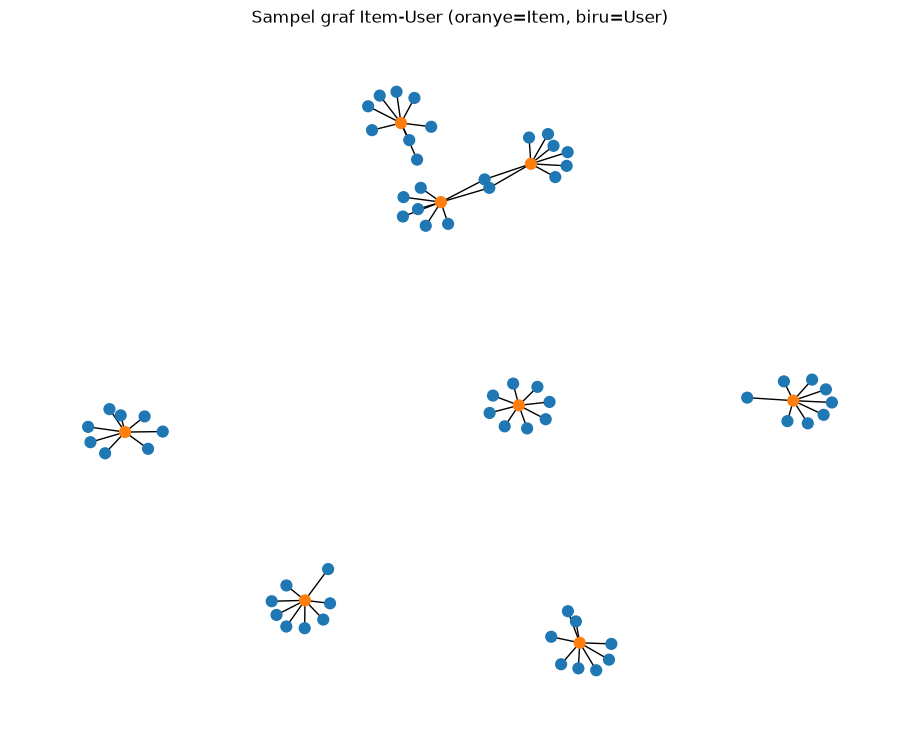

In [6]:
# Plot soal 5: item populer
top_items = p1["itemid"].value_counts().head(8).index
sub2 = p1[p1["itemid"].isin(top_items)].drop_duplicates(["visitorid", "itemid"])
sub2 = sub2.groupby("itemid").head(8)

G2 = nx.Graph()
for _, r in sub2.iterrows():
    G2.add_edge(f"I{r.itemid}", f"U{r.visitorid}")
warna2 = ["tab:orange" if n.startswith("I") else "tab:blue" for n in G2.nodes]
plt.figure(figsize=(9, 7))
nx.draw_spring(G2, node_color=warna2, node_size=60, with_labels=False)
plt.title("Sampel graf Item-User (oranye=Item, biru=User)")
plt.show()

Soal 5 VSM untuk Item (Item × User)

Ini kebalikan (transpose) dari matriks user: tiap item jadi vektor sebanyak user.

Jawaban:
- Shape: 190.110 × 868.935, sparsity 99,9992%, memori 16,5 MB
- Rata-rata 6,88 user per item
- Item dengan ≥ 2 user: 116.886 (61,5%)

Plot memakai 8 item terpopuler (oranye = item, biru = user). Item lebih sedikit tetapi lebih banyak user.

== User: 10 pasangan dengan jarak terendah ==
       A        B  cosine  jarak
 U273161  U625639  0.7351 0.2649
 U947204 U1355165  0.7217 0.2783
 U273161  U701644  0.7213 0.2787
 U273161  U548657  0.7213 0.2787
 U273161  U690592  0.7213 0.2787
U1196175 U1355165  0.7071 0.2929
 U548657  U879371  0.7071 0.2929
 U519209  U548657  0.7071 0.2929
 U548657 U1156188  0.6804 0.3196
 U548657  U625639  0.6794 0.3206


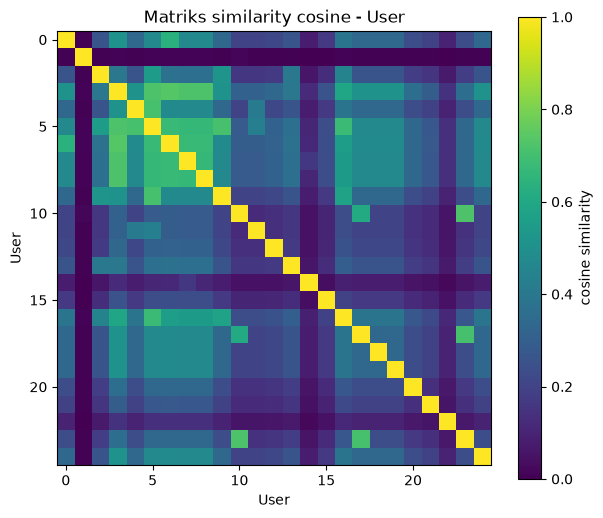

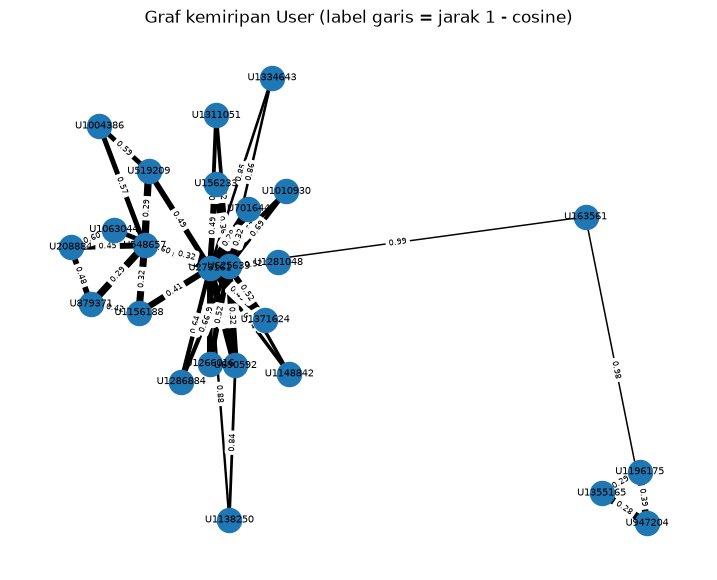

== Item: 10 pasangan dengan jarak terendah ==
      A       B  cosine  jarak
I219512 I384302  0.2123 0.7877
I370653 I335975  0.1856 0.8144
I234255 I290999  0.1641 0.8359
I309778 I257040  0.1181 0.8819
I441668 I112782  0.1030 0.8970
 I48030 I161623  0.0939 0.9061
 I48030 I112782  0.0898 0.9102
I335975  I91755  0.0885 0.9115
I234255  I48030  0.0873 0.9127
I219512 I161623  0.0866 0.9134


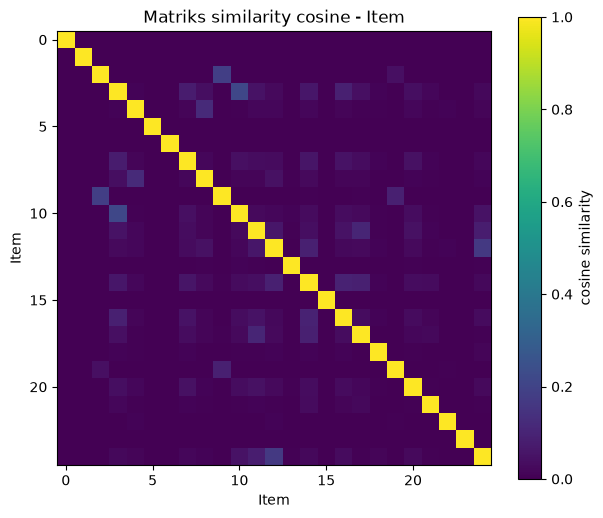

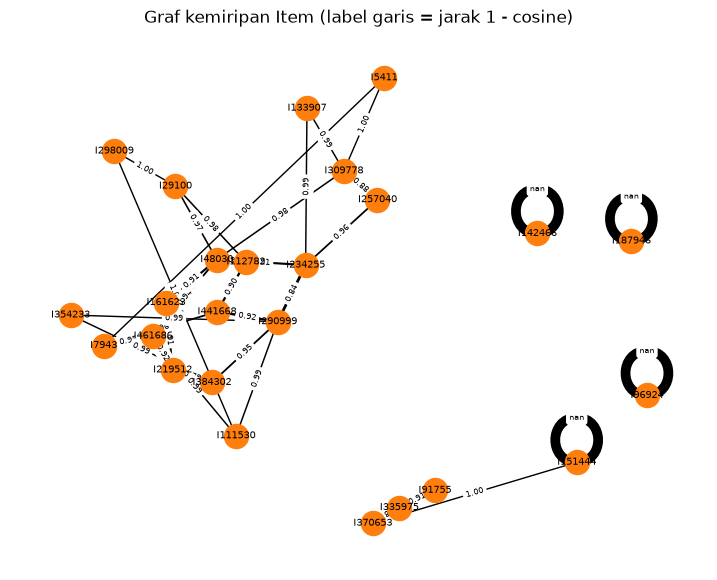

Shape matriks similarity: (25, 25) (25, 25)


In [7]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

user_cats = user_ids.cat.categories
item_cats = item_ids.cat.categories
ref_idx = int(np.argmax(item_deg))          # item acuan (5411)

def analisis_kemiripan(M, labels, nama, awalan, k=2, top=10):
    S = cosine_similarity(M)                     # similarity cosine (n x n)
    D = np.clip(1 - S, 0, None)                  # jarak = 1 - cosine
    np.fill_diagonal(D, np.nan)                  # abaikan diri sendiri
    kol = [f"{awalan}{l}" for l in labels]
    S_df = pd.DataFrame(S, index=kol, columns=kol)
    D_df = pd.DataFrame(D, index=kol, columns=kol)

    # Pasangan dengan jarak TERENDAH (= paling mirip)
    iu = np.triu_indices(len(labels), k=1)
    pasangan = pd.DataFrame({"A": np.array(kol)[iu[0]], "B": np.array(kol)[iu[1]],
                             "cosine": S[iu], "jarak": D[iu]})
    pasangan = pasangan[pasangan["cosine"] > 0].sort_values("jarak").head(top)
    print(f"== {nama}: {top} pasangan dengan jarak terendah ==")
    print(pasangan.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

    # Heatmap matriks similarity
    plt.figure(figsize=(7, 6))
    plt.imshow(S, cmap="viridis", vmin=0, vmax=1)
    plt.colorbar(label="cosine similarity")
    plt.title(f"Matriks similarity cosine - {nama}")
    plt.xlabel(nama); plt.ylabel(nama)
    plt.show()

    # Graf: tiap simpul dihubungkan ke k tetangga berjarak terendah
    G = nx.Graph()
    G.add_nodes_from(kol)
    for a in range(len(labels)):
        urut = [j for j in np.argsort(np.nan_to_num(D[a], nan=9)) if S[a, j] > 0][:k]
        for b in urut:
            G.add_edge(kol[a], kol[b], jarak=float(D[a, b]), cos=float(S[a, b]))
    lebar = [1 + 6 * G[u][v]["cos"] for u, v in G.edges]
    plt.figure(figsize=(9, 7))
    pos = nx.spring_layout(G, seed=42, weight="cos")
    nx.draw_networkx(G, pos, node_size=300, font_size=7, width=lebar,
                     node_color="tab:blue" if awalan == "U" else "tab:orange")
    nx.draw_networkx_edge_labels(
        G, pos, edge_labels={(u, v): f"{d['jarak']:.2f}" for u, v, d in G.edges(data=True)},
        font_size=6)
    plt.title(f"Graf kemiripan {nama} (label garis = jarak 1 - cosine)")
    plt.axis("off"); plt.show()
    return S_df, D_df, G

# ---- USER x USER ----
ref_users = X_item[ref_idx].indices                  # user yang menyentuh item acuan
cand = ref_users[user_deg[ref_users] >= 3]
rng = np.random.default_rng(42)
sub_u = np.sort(rng.choice(cand, size=min(25, len(cand)), replace=False))
S_user, D_user, G_user = analisis_kemiripan(
    X[sub_u], [int(user_cats[i]) for i in sub_u], "User", "U")

# ---- ITEM x ITEM ----
sub_i = np.argsort(-item_deg)[:25]
S_item, D_item, G_item = analisis_kemiripan(
    X_item[sub_i], [int(item_cats[i]) for i in sub_i], "Item", "I")

print("Shape matriks similarity:", S_user.shape, S_item.shape)

In [8]:
S_user.round(2)    # similarity cosine User x User
D_user.round(2)    # jarak (1 - cosine) User x User
S_item.round(2)    # similarity cosine Item x Item
D_item.round(2)    # jarak (1 - cosine) Item x Item

,I5411,I187946,I370653,I219512,I309778,I298009,I96924,I461686,I257040,I335975,...,I151444,I161623,I112782,I111530,I91755,I7943,I29100,I133907,I142466,I290999
I5411,NaN,1.0,1.00,1.00,1.00,1.0,1.0,1.00,1.00,1.00,...,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.00
I187946,1.0,NaN,1.00,1.00,1.00,1.0,1.0,1.00,1.00,1.00,...,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.00
I370653,1.0,1.0,NaN,1.00,1.00,1.0,1.0,1.00,1.00,0.81,...,1.0,1.00,1.00,1.00,0.96,1.00,1.00,1.00,1.0,1.00
I219512,1.0,1.0,1.00,NaN,0.99,1.0,1.0,0.92,0.96,1.00,...,1.0,0.91,0.96,0.99,1.00,0.96,0.98,1.00,1.0,0.98
I309778,1.0,1.0,1.00,0.99,NaN,1.0,1.0,0.99,0.88,1.00,...,1.0,0.99,0.99,1.00,1.00,0.98,0.99,0.99,1.0,0.98
I298009,1.0,1.0,1.00,1.00,1.00,NaN,1.0,1.00,1.00,1.00,...,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.00
I96924,1.0,1.0,1.00,1.00,1.00,1.0,NaN,1.00,1.00,1.00,...,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.00
I461686,1.0,1.0,1.00,0.92,0.99,1.0,1.0,NaN,0.98,1.00,...,1.0,0.95,0.97,0.99,1.00,0.95,0.99,1.00,1.0,0.98
I257040,1.0,1.0,1.00,0.96,0.88,1.0,1.0,0.98,NaN,1.00,...,1.0,0.99,0.99,1.00,1.00,0.99,0.99,1.00,1.0,0.99
I335975,1.0,1.0,0.81,1.00,1.00,1.0,1.0,1.00,1.00,NaN,...,1.0,1.00,0.99,1.00,0.91,1.00,1.00,1.00,1.0,1.00


### Tambahan: matriks similarity, jarak, dan graf kemiripan

Matriks similarity penuh tidak bisa dihitung (User × User ± 6 TB, Item × Item ± 289 GB), jadi dihitung pada **sampel 25 simpul**:
- **User:** 25 user acak (seed 42) yang pernah menyentuh item 5411 dan punya ≥ 3 item.
- **Item:** 25 item terpopuler.

**Langkah:**
1. Hitung **cosine similarity** antar vektor (0 = tidak ada kesamaan, 1 = identik).
2. Hitung **jarak = 1 − cosine**. Makin kecil jaraknya, makin mirip.
3. Ambil pasangan dengan **jarak terendah** (paling mirip), tanpa pasangan dengan dirinya sendiri.
4. Graf: tiap simpul dihubungkan ke 2 tetangga dengan jarak terendah. Label garis = jarak, garis lebih tebal = lebih mirip.

**Hasil:**

**User × User** (25 user sampel)
- Pasangan paling mirip: visitor **273161** dan **625639**, cosine **0,7351**, jarak **0,2649**.
- Sepuluh pasangan terendah memiliki jarak 0,2649 sampai 0,3206 (cosine 0,68 sampai 0,74).
- Visitor **548657** muncul di 5 dari 10 pasangan, dan visitor **273161** di 4 pasangan. Keduanya menjadi pusat kmiripan di antara sampel.

**Item × Item** (25 item terpopuler)
- Pasangan paling mirip: item **219512** dan **384302**, cosine **0,2123**, jarak **0,7877**.
- Sepuluh pasangan terendah memiliki jarak 0,7877 sampai 0,9134 (cosine 0,09 sampai 0,21).
- Item **48030** muncul di 3 pasangan.

**Interpretasi:**
- Kemiripan antar-user pada sampel ini **lebih tinggi** (cosine ≈ 0,7) daripada antar-item (cosine ≈ 0,2).

Soal 6 Proyeksi mana yang lebih baik?

| | User | Item |
|---|---|---|
| Jumlah simpul | 868.935 | 190.110 (4,6× lebih sedikit) |
| Ukuran matriks similarity | ± 7,55 × 10¹¹ | ± 3,61 × 10¹⁰ (± 21× lebih kecil) |
| Rata-rata interaksi | 1,51 | 6,88 |
| Simpul dengan ≥ 2 interaksi | 19,6% | 61,5% |

Jawaban: proyeksi Item lebih baik.
- **Efisien:** simpul lebih sedikit, matriks kemiripan jauh lebih kecil.
- **Efektif:** user kebanyakan hanya punya 1 item, jadi kemiripannya hampir selalu 0. Item disentuh ± 7 user, jadi kemiripannya lebih bermakna.

In [6]:
from sklearn.preprocessing import normalize

item_cats = item_ids.cat.categories          # indeks -> itemid asli
X_item_n = normalize(X_item, norm="l2")      # baris dinormalisasi, cosine = dot product

# Item acuan: yang paling banyak user-nya
ref_idx = int(np.argmax(item_deg))
ref_itemid = int(item_cats[ref_idx])
print("Item acuan:", ref_itemid, "| jumlah user:", item_deg[ref_idx])

sim = (X_item_n @ X_item_n[ref_idx].T).toarray().ravel()
sim[ref_idx] = -1                           

top5 = np.argsort(-sim)[:5]
for i in top5:
    print(int(item_cats[i]), round(float(sim[i]), 4))

Item acuan: 5411 | jumlah user: 1844
33030 0.1552
37807 0.1067
33956 0.1065
256242 0.0864
459936 0.0842


### Penjelasan kode: memilih 5 item paling mirip

```python
sim = (X_item_n @ X_item_n[ref_idx].T).toarray().ravel()
sim[ref_idx] = -1
top5 = np.argsort(-sim)[:5]
```

**1. `sim = ...`** menghitung cosine similarity item acuan terhadap **semua** item. Karena baris sudah dinormalisasi, cosine sama dengan dot product. Hasilnya satu angka kemiripan per item.

**2. `sim[ref_idx] = -1`** menyingkirkan item acuan dari hasil.
- Kemiripan item dengan dirinya sendiri selalu **1** (nilai tertinggi), sehingga tanpa baris ini item acuan menjadi peringkat 1.
- Akibatnya top-5 hanya berisi **4 item lain** (satu slot terpakai oleh item acuan sendiri).
- Dipakai **-1**, bukan 0, karena cosine pada data ini bernilai 0 sampai 1. Nilai -1 pasti paling rendah, sedangkan 0 bisa seri dengan banyak item yang kemiripannya memang 0.

**3. `np.argsort(-sim)[:5]`** mengambil 5 item dengan kemiripan tertinggi.
- `np.argsort` mengurutkan dari yang **terkecil**, lalu mengembalikan nomor urutnya.
- Tanda minus membalik nilai, sehingga kemiripan **terbesar** menjadi yang paling kecil dan muncul pertama.
- Tanpa tanda minus, yang terambil adalah 5 item **paling tidak mirip** (item acuan yang bernilai -1 lalu item dengan kemiripan 0).

| Variasi kode | Hasil |
|---|---|
| Benar (`-1` dan `-sim`) | 5 item paling mirip, item acuan tidak ikut |
| Tanpa `sim[ref_idx] = -1` | Item acuan ikut jadi peringkat 1, hanya 4 item lain |
| Tanpa tanda minus | 5 item paling tidak mirip |

In [4]:
top_items_idx = np.argsort(-item_deg)[:100]
pairs = []
for idx in top_items_idx:
    s = (X_item_n @ X_item_n[idx].T).toarray().ravel()
    s[idx] = -1
    for j in np.argsort(-s)[:5]:
        if s[j] > 0:
            pairs.append({"a": int(item_cats[idx]),
                          "b": int(item_cats[j]),
                          "score": round(float(s[j]), 4)})
print(len(pairs), "pasangan SIMILAR_TO")
pairs[:3]

500 pasangan SIMILAR_TO


[{'a': 5411, 'b': 33030, 'score': 0.1552},
 {'a': 5411, 'b': 37807, 'score': 0.1067},
 {'a': 5411, 'b': 33956, 'score': 0.1065}]

In [7]:
driver.execute_query("""
UNWIND $pairs AS p
MATCH (a:Item {itemId: p.a})
MATCH (b:Item {itemId: p.b})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.score = p.score
""", pairs=pairs, database_="neo4j")
print("SIMILAR_TO ditulis")

SIMILAR_TO ditulis


In [10]:
rec, _, _ = driver.execute_query("""
MATCH (a:Item {itemId: $ref})-[r:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS mirip, r.score AS similarity
ORDER BY r.score DESC LIMIT 5
""", ref=ref_itemid, database_="neo4j")
for r in rec: print(r["acuan"], r["mirip"], r["similarity"])

5411 33030 0.1552
5411 37807 0.1067
5411 33956 0.1065
5411 256242 0.0864
5411 459936 0.0842


Soal 7 Menghitung similarity pada proyeksi Item

Memakai cosine similarity pada matriks Item × User. Matriks penuh terlalu besar, jadi dihitung per item acuan. Item acuan: 5411 (item dengan user terbanyak, 1.844 user).

Top-5 paling mirip dengan item 5411:
| Item | Cosine |
|---|---|
| 33030 | 0,1552 |
| 37807 | 0,1067 |
| 33956 | 0,1065 |
| 256242 | 0,0864 |
| 459936 | 0,0842 |

Nilainya kecil karena datanya sangat jarang. Dihitung juga top-5 untuk 100 item terpopuler, hasilnya 500 relasi `SIMILAR_TO`.

(a) Cypher top-5:
```cypher
MATCH (a:Item {itemId: 5411})-[r:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS mirip, r.score AS similarity
ORDER BY r.score DESC LIMIT 5
```
(b) Menulis nilai ke graf: `MERGE` membuat relasi `SIMILAR_TO` (tanpa duplikat), lalu `SET r.score` menyimpan nilai cosine-nya.

Soal 8 Kondisi sebelum dan sesudah similarity

Query dijalankan di Neo4j Desktop (Query tool, database `neo4j`).

#### SEBELUM
```cypher
MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS jumlah_similar_to
```
Hasil: `0`

> ![sebelum](Gambar/s1_count0.png)

```cypher
MATCH (v:Visitor)-[r:VIEWED]->(i:Item {itemId: 5411})
RETURN v, r, i LIMIT 10
```

>    ![Graf sebelum](Gambar/s2_graf_sebelum.png)

Graf berbentuk bintang: item 5411 di tengah, dikelilingi visitor yang melihatnya. Belum ada hubungan antar-item.

#### SESUDAH
```cypher
MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS jumlah_similar_to
```
Hasil: `500`

```cypher
MATCH (a:Item {itemId: 5411})-[s:SIMILAR_TO]->(b:Item)
RETURN a, s, b
```

>    ![Graf sesudah](Gambar/s4_graf_sesudah.png)

Graf berubah: item 5411 sekarang punya 5 panah `SIMILAR_TO` ke item lain (33030, 37807, 33956, 256242, 459936). Setiap panah membawa nilai `score` (cosine similarity) yang tersimpan di relasinya. Jadi graf tidak lagi hanya menunjukkan siapa melihat apa, tetapi juga item mana yang mirip dengan item lain.

| | Sebelum | Sesudah |
|---|---|---|
| Jumlah relasi `SIMILAR_TO` | 0 | 500 |
| Simpul yang tampil | Visitor dan Item | Item |
| Relasi yang tampil | VIEWED (Visitor → Item) | SIMILAR_TO (Item → Item) |
| Makna | Siapa melihat apa | Item mana yang mirip |

Perbedaan 0 menjadi 500 berasal dari perhitungan cosine similarity pada proyeksi Item (Soal 7): 100 item terpopuler masing-masing mendapat 5 item paling mirip, sehingga 100 × 5 = 500 relasi.

2.2 Analytics

Soal 1 Memilih user secara acak (bisa diulang hasilnya)
Cara memilih:
1. Ambil user yang ada di P1 dan P2 (16.766 user), supaya ada kunci jawaban.
2. Ambil yang punya minimal 3 item di P1 → 4.145 kandidat.
3. Acak dengan `np.random.default_rng(42).choice(kandidat)`. Karena seed-nya tetap (42), hasilnya selalu sama.

User terpilih: 124145 (10 item di P1, 1 item di P2: 439807).

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import normalize

p2 = pd.read_csv("events_p2.csv")

user_cats = user_ids.cat.categories      # indeks baris -> visitorid
item_cats = item_ids.cat.categories      # indeks kolom -> itemid
uidx = pd.Series(np.arange(len(user_cats)), index=user_cats)
user_deg = np.diff(X.indptr)

# Kandidat: ada di P1 dan P2, dan punya >= 3 item berbeda di P1
irisan = np.intersect1d(user_cats, p2["visitorid"].unique())  
kandidat = irisan[user_deg[uidx[irisan].values] >= 3]
print("Irisan P1&P2:", len(irisan), "| kandidat (>=3 item di P1):", len(kandidat))

SEED = 42
rng = np.random.default_rng(SEED)
target = int(rng.choice(kandidat))
print("SEED =", SEED, "| user terpilih:", target)

Irisan P1&P2: 16766 | kandidat (>=3 item di P1): 4145
SEED = 42 | user terpilih: 124145


In [ ]:
X_n = normalize(X, norm="l2")   # baris user dinormalisasi -> cosine = dot product

def recommend_knn(visitorid, k=5, topn=5, pool=500, hanya_tetangga_berguna=True):
    u = uidx[visitorid]
    sims = (X_n @ X_n[u].T).toarray().ravel()
    sims[u] = -1
    seen = set(X[u].indices)

    urut = np.argsort(-sims, kind="stable")
    if hanya_tetangga_berguna:
        cand = [n for n in urut[:pool] if sims[n] > 0 and (set(X[n].indices) - seen)]
        nn = np.array(cand[:k], dtype=int)
    else:                                    
        nn = urut[:k]
        nn = nn[sims[nn] > 0]

    skor = {}
    for n in nn:
        row = X_n[n]
        for j, w in zip(row.indices, row.data):
            if j not in seen:
                skor[j] = skor.get(j, 0.0) + sims[n] * w
    ranked = sorted(skor.items(), key=lambda t: -t[1])[:topn]
    return nn, sims, ranked

def evaluasi(rec_items, gt, K=5):
    rel = [1 if i in gt else 0 for i in rec_items[:K]]
    hit = int(any(rel))
    dcg = sum(r / np.log2(pos + 2) for pos, r in enumerate(rel))
    idcg = sum(1 / np.log2(pos + 2) for pos in range(min(len(gt), K)))
    ndcg = dcg / idcg if idcg > 0 else 0.0
    return hit, ndcg, rel

gt = set(p2.loc[p2["visitorid"] == target, "itemid"].astype(int))
print("Fungsi siap. Kunci jawaban P2 user", target, ":", sorted(gt))

Fungsi siap. Kunci jawaban P2 user 124145 : [439807]


(a) Cara kerja KNN
1. Ubah tiap user jadi vektor, lalu hitung kemiripan (cosine) user target dengan semua user lain.
2. Ambil k = 5 tetangga paling mirip.
3. Beri skor ke item milik tetangga yang belum dilihat user target: skor = kemiripan tetangga × bobot item.
4. Urutkan skor. Top-3 = item iklan, top-5 dipakai untuk menghitung metrik.

Data P2 tidak dipakai membangun model, hanya sebagai kunci jawaban.

In [10]:
nn_m, sims_m, ranked_m = recommend_knn(target, k=5, topn=5, hanya_tetangga_berguna=False)
seen = set(X[uidx[target]].indices)

print("Item P1 milik user:", sorted(int(item_cats[j]) for j in seen))
print("Jumlah rekomendasi KNN murni:", len(ranked_m), "\n")
for n in nn_m:
    items_n = set(X[n].indices)
    print(f"visitor {int(user_cats[n])} | cosine = {sims_m[n]:.4f} | "
          f"item tetangga: {[int(item_cats[j]) for j in items_n]} | "
          f"item baru: {[int(item_cats[j]) for j in items_n - seen]}")

Item P1 milik user: [59565, 105781, 153266, 175819, 208666, 236437, 270121, 378219, 415472, 445398]
Jumlah rekomendasi KNN murni: 0 

visitor 461275 | cosine = 0.7071 | item tetangga: [445398] | item baru: []
visitor 1265649 | cosine = 0.7071 | item tetangga: [445398] | item baru: []
visitor 2813 | cosine = 0.2357 | item tetangga: [59565] | item baru: []
visitor 176655 | cosine = 0.2357 | item tetangga: [208666] | item baru: []
visitor 274289 | cosine = 0.2357 | item tetangga: [415472] | item baru: []


Temuan: KNN murni menghasilkan 0 rekomendasi
Kelima tetangga teratas masing-masing hanya punya 1 item, dan item itu sudah dimiliki user target. Karena kita hanya merekomendasikan item yang belum pernah dilihat, tidak ada yang bisa direkomendasikan.

Sifat data: sekitar 80% user hanya punya 1 item, sedangkan user target punya 10 item.

Perbaikan: pilih tetangga yang punya item baru
Soal meminta 3 item iklan, jadi cara memilih tetangga diubah: ambil 500 user paling mirip, saring yang punya minimal 1 item baru, lalu ambil 5 teratas. Nilai **k tetap 5**, rumus skor tidak berubah, dan **user tidak diganti**.

In [12]:
nn, sims, ranked = recommend_knn(target, k=5, topn=5, pool=500)
seen = set(X[uidx[target]].indices)

print("5 tetangga (yang punya item baru):")
for n in nn:
    baru = [int(item_cats[j]) for j in set(X[n].indices) - seen]
    print(f"  visitor {int(user_cats[n])} | cosine = {sims[n]:.4f} | item baru: {baru}")

print("\nRekomendasi KNN (top-5):")
for r, (j, s) in enumerate(ranked, 1):
    print(f"  {r}. item {int(item_cats[j])} | skor = {s:.4f}")

5 tetangga (yang punya item baru):
  visitor 444837 | cosine = 0.2287 | item baru: [378577]
  visitor 695912 | cosine = 0.2287 | item baru: [194537]
  visitor 5834 | cosine = 0.2108 | item baru: [399593]
  visitor 1135289 | cosine = 0.1925 | item baru: [103306, 432676]
  visitor 206399 | cosine = 0.1667 | item baru: [249413]

Rekomendasi KNN (top-5):
  1. item 249413 | skor = 0.1179
  2. item 399593 | skor = 0.0943
  3. item 103306 | skor = 0.0786
  4. item 432676 | skor = 0.0786
  5. item 378577 | skor = 0.0555


In [13]:
iklan = [int(item_cats[j]) for j, _ in ranked[:3]]
print("3 item iklan untuk user", target, ":", iklan)

rec5 = [int(item_cats[j]) for j, _ in ranked]
hit, ndcg, rel = evaluasi(rec5, gt, K=5)
print("Ground truth P2 :", sorted(gt))
print("Rekomendasi     :", rec5)
print("Relevansi       :", rel)
print(f"Hit@5 = {hit} | NDCG@5 = {ndcg:.4f}")
hit3, ndcg3, _ = evaluasi(rec5, gt, K=3)
print(f"Hit@3 = {hit3} | NDCG@3 = {ndcg3:.4f}")

3 item iklan untuk user 124145 : [249413, 399593, 103306]
Ground truth P2 : [439807]
Rekomendasi     : [249413, 399593, 103306, 432676, 378577]
Relevansi       : [0, 0, 0, 0, 0]
Hit@5 = 0 | NDCG@5 = 0.0000
Hit@3 = 0 | NDCG@3 = 0.0000


(b) 3 item yang diiklankan (k = 5)

| Visitor tetangga | Cosine | Item baru |
|---|---|---|
| 444837 | 0,2287 | 378577 |
| 695912 | 0,2287 | 194537 |
| 5834 | 0,2108 | 399593 |
| 1135289 | 0,1925 | 103306, 432676 |
| 206399 | 0,1667 | 249413 |

Top-5: 249413, 399593, 103306, 432676, 378577.

**Jawaban 1b: item yang diiklankan = 249413, 399593, 103306**

Soal 2 — Evaluasi
Kunci jawaban (item user di P2) = `{439807}`.
- **Hit@5** = 1 bila ada minimal satu rekomendasi yang benar, selain itu 0.
- **NDCG@5** = nilai yang lebih tinggi bila item benar muncul di peringkat atas (0 sampai 1).

| | Nilai |
|---|---|
| (a) Hit@5 | **0** |
| (b) NDCG@5 | **0,0000** |

Item 439807 tidak ada di 5 rekomendasi. kunci jawabannya hanya 1 item di antara ± 190 ribu item.

soal meminta 3 item iklan tetapi metrik @5, jadi metrik dihitung dari top-5 dan top-3 ditampilkan sebagai iklan. Hit@3 dan NDCG@3 juga ditampilkan sebagai pembanding.

In [21]:
rng2 = np.random.default_rng(SEED)
sampel = rng2.choice(kandidat, size=300, replace=False)

gt_all = p2.groupby("visitorid")["itemid"].apply(lambda s: set(s.astype(int)))

hasil = []
for v in sampel:
    _, _, rk = recommend_knn(int(v), k=5, topn=5)
    rec = [int(item_cats[j]) for j, _ in rk]
    h, n, _ = evaluasi(rec, gt_all[int(v)], K=5)
    hasil.append((h, n))

hasil = np.array(hasil)
print(f"Rata-rata Hit@5  : {hasil[:,0].mean():.4f}")
print(f"Rata-rata NDCG@5 : {hasil[:,1].mean():.4f}  (n = {len(sampel)} user)")

Rata-rata Hit@5  : 0.0533
Rata-rata NDCG@5 : 0.0156  (n = 300 user)


Evaluasi pelengkap: 300 user acak
Supaya tidak bergantung pada satu user, evaluasi diulang pada 300 user acak (seed 42).

| | Rata-rata |
|---|---|
| Hit@5 | 0,0533 |
| NDCG@5 | 0,0156 |

Sekitar 5% user mendapat minimal satu rekomendasi yang tepat, jadi hasil 0 pada user 124145 adalah hal yang umum.

Keterbatasan: data sangat jarang; item yang sudah dilihat di P1 tidak direkomendasikan padahal bisa dilihat lagi di P2; P2 hanya 3 minggu; dan KNN dimodifikasi karena versi murninya kosong.

Kesimpulan
1. Graf P1: 868.935 Visitor, 190.110 Item, 1.678.419 relasi.
2. Proyeksi Item lebih baik daripada proyeksi User.
3. Kemiripan antar-item disimpan sebagai 500 relasi `SIMILAR_TO`.
4. Untuk user 124145 (k = 5), item iklan: 249413, 399593, 103306. Hit@5 = 0, NDCG@5 = 0.
5. Pada 300 user, rata-rata Hit@5 = 0,0533 dan NDCG@5 = 0,0156.